In [1]:
import os
import re
from utils import *
from scipy.linalg import expm
from scipy.optimize import minimize
import matplotlib.ticker as ticker

In [2]:
def get_data(params, config):
    dir = f"{params}_params/sq_error_sweep/config_{config}/"
    subdirs = os.listdir(dir)
    
    if "extra" in subdirs:
        subdirs.remove("extra")

    overlaps = np.zeros((len(subdirs), 21, 4, 4), np.complex64)
    initial_energies = np.zeros((len(subdirs), 21, 4))

    # Define a regular expression pattern to match the subdirectory names
    pattern = re.compile(r"t_ramp_(\d+\.?\d*)_(\d+\.?\d*)-(\d+\.?\d*)-0.01")

    # Parse out the values of t_min, t_max, t_step and sigma.
    parsed_values = []
    for i, subdir in enumerate(subdirs):
        match = pattern.match(subdir)
        a, b, c = match.groups()
        parsed_values.append(float(a))
        for j, t in enumerate(np.arange(float(b), float(c)+0.005, 0.01)):
            _, energy, ol, _ = np.load(dir + subdir + f"/t_hold_{t:.2f}.npz").values()
            overlaps[i, j] = ol[-1, [0,1,2,4]]
            initial_energies[i, j] = energy[0].real


    ramp_times = np.array(parsed_values)
    sort_inds = np.argsort(ramp_times)
    ramp_times = ramp_times[sort_inds]
    overlaps = overlaps[sort_inds]

    return ramp_times, np.arange(float(b), float(c)+0.005, 0.01), overlaps, initial_energies

In [3]:
def process_data(config, params):
    ramp_times, hold_times, overlaps, energies = get_data(params, config)

    fid_fun = partial(fidelity, U_0=sqrt_iSWAP if config == "II" else CZ)
    fid = np.zeros((len(ramp_times), len(hold_times)))
    corr_angles = np.zeros((len(ramp_times), len(hold_times), 2))

    for i in range(len(ramp_times)):
        for j in range(len(hold_times)):
            a1, a2, a3 = phase_corr_angles(overlaps[i, j])
            opt_correction = minimize(
                lambda x: -fidelity_opt_correction(x, overlaps[i, j], fid_fun),
                [(a2) % (2 * np.pi), (a3) % (2 * np.pi)],
                method="Nelder-Mead",
            )

            fid[i, j] = -opt_correction.fun
            corr_angles[i, j] = opt_correction.x
            assert opt_correction.success

    ind = np.unravel_index(fid.argmax(), fid.shape)
    print(ind)
    U = SQ_rotation(corr_angles[*ind], overlaps[*ind])
    U = np.exp(-1j * np.angle(U[0, 0])) * U
    print(
        f"Ramp time: {ramp_times[ind[0]]:.2f} ns, hold time: {hold_times[ind[1]]:.2f} ns, fidelity: {fid[*ind]}"
    )
    Latex(bmatrix(U))

    return fid

In [4]:
zz_II = process_data("II", "zz_II")
zz_III = process_data("III", "zz_III")
beta_II = process_data("II", "beta")
beta_III = process_data("III", "beta")

(np.int64(11), np.int64(9))
Ramp time: 1.42 ns, hold time: 0.09 ns, fidelity: 0.998949815960859
(np.int64(11), np.int64(8))
Ramp time: 1.31 ns, hold time: 8.31 ns, fidelity: 0.9962082666533947
(np.int64(10), np.int64(10))
Ramp time: 0.49 ns, hold time: 0.56 ns, fidelity: 0.9719525339595431
(np.int64(8), np.int64(12))
Ramp time: 3.09 ns, hold time: 3.21 ns, fidelity: 0.996245965462922


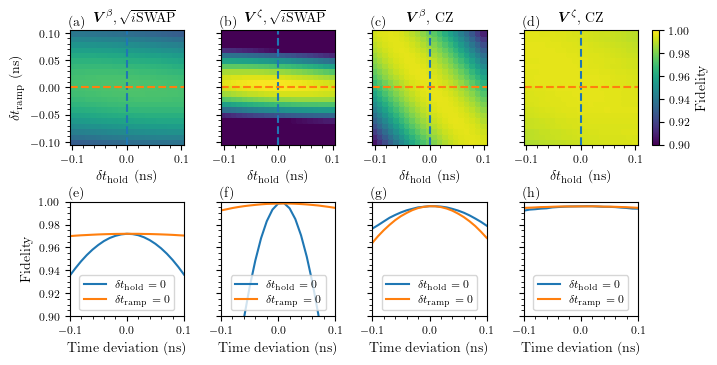

In [5]:
inches_per_pt = 1 / 72.27
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    "font.family": "cmr",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "text.latex.preamble": r"\usepackage[OT1]{fontenc}\usepackage{physics}"

}

plt.rcParams.update(tex_fonts)


fig, axs = plt.subplots(
    2,
    4,
    figsize=(510 * inches_per_pt, (510 * 6 / 12) * inches_per_pt),
    sharex="row",
    sharey="row"
    )

dt = np.arange(-0.1, 0.105, 0.01)

def plot(ax, data):
    ax[0].pcolormesh(
        dt,
        dt,
        data,
        vmin=0.9,
        vmax=1,
        linewidth=0.01,
        edgecolors="face",
    )
    ax[0].set_xlabel(r"$\delta t_\mathrm{hold}$ (ns)")
    ax[0].set_aspect("equal")
    ax[0].axvline(0, color="C0", ls="--")
    ax[0].axhline(0, color="C1", ls="--")

    ax[1].plot(dt, data[:, 10], label=r"$\delta t_\mathrm{hold} = 0$")
    ax[1].plot(dt, data[10], label=r"$\delta t_\mathrm{ramp} = 0$")
    ax[1].set_xlabel("Time deviation (ns)")
    ax[1].set_ylim(0.9, 1.0)
    ax[1].set_xlim(-0.1, 0.1)
    ax[1].set_aspect(2)
    ax[1].legend(loc="lower center")


plot(axs[:, 0], beta_II)
plot(axs[:, 1], zz_II)
plot(axs[:, 2], beta_III)
plot(axs[:, 3], zz_III)

axs[0, 0].set_ylabel(r"$\delta t_\mathrm{ramp}$ (ns)")
axs[1, 0].set_ylabel("Fidelity")

plt.subplots_adjust(left = 0.085, top=0.93, bottom=0.12, right=0.9, wspace=0.25, hspace=0.5)

cbar_ax = fig.add_axes(
    [
        axs[0, 3].get_position().x1 + 0.02,
        axs[0, 3].get_position().y0,
        0.01,
        axs[0, 3].get_position().y1 - axs[0, 3].get_position().y0,
    ]
)

cbar = fig.colorbar(
    axs[0, 3].collections[0],
    cax=cbar_ax,
    ax=axs[0,3],
    label = "Fidelity"
)

label = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)", "(g)", "(h)"]
for i, ax in enumerate(axs.ravel()):
    ax.text(-0.01, 1.01, label[i], transform=ax.transAxes, ha="left", va="bottom")
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

titles = [
    r"$\vb*{V}^\beta,\sqrt{i\mathrm{SWAP}}$", 
    r"$\vb*{V}^\zeta,\sqrt{i\mathrm{SWAP}}$", 
    r"$\vb*{V}^\beta$, CZ", 
    r"$\vb*{V}^\zeta$, CZ"
]
for i, a in enumerate(axs[0, :]):
    if i < 2:
        a.set_title(titles[i], loc="left", x=0.2)
    else:
        a.set_title(titles[i])

plt.savefig("figs/all_errors.pdf", dpi=600)
plt.show()